# Exercise 3: Convolutions, Autoencoders & Variational Autoencoders

# Prerequisites
Please install Python and the required libraries for this exercise, or do it in Google Colab. We use [PyTorch](https://pytorch.org/get-started/locally/), as in the lecture.

Besides PyTorch you need the `medmnist` package (`pip install medmnist`, or uncomment the first line of the next cell in Colab).

The import statements of the solution we prepared are specified below, however feel free to use any other library.

## Data
We work with **BloodMNIST** (Yang et al., *MedMNIST v2*, Scientific Data 2023). It contains ~17,000 microscope images of single blood cells from peripheral blood smears of healthy donors, each labelled with one of 8 cell types: basophil, eosinophil, erythroblast, immature granulocyte, lymphocyte, monocyte, neutrophil and platelet. Counting these cell types (the *differential blood count*) is one of the most common tests in the clinic, e.g. to detect infections or to screen for leukaemia, and is increasingly automated with deep learning.

The images are downscaled to 28 × 28 pixels with 3 colour channels (RGB). The colour comes from the staining of the smear and carries information about the cell type.

**Total: 20 points.** Questions are part of the points, answer them in 1–3 sentences in the markdown cells.

In [71]:
# !pip install medmnist
# These are the libraries that we used - feel free to use others if you want
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.decomposition import PCA
from medmnist import BloodMNIST

torch.manual_seed(0)
np.random.seed(0)

# 1)
Load the data and get to know it. (1 point)

- Plot one example image of each of the 8 cell types, with the cell type as title.
- How many images of each cell type are there in the training set (a bar plot is enough)? Is the dataset balanced?

In [72]:
# Load data (downloads ~35 MB the first time)
train_set = BloodMNIST(split="train", download=True, size=28)
test_set = BloodMNIST(split="test", download=True, size=28)

X_train_img = train_set.imgs          # shape (n_images, 28, 28, 3), values 0-255
y_train = train_set.labels.ravel()    # cell type 0-7 # .ravel makes it one dimensional
X_test_img = test_set.imgs
y_test = test_set.labels.ravel()

class_names = ["basophil", "eosinophil", "erythroblast", "immature granulocyte",
               "lymphocyte", "monocyte", "neutrophil", "platelet"]
print(X_train_img.shape, X_test_img.shape)

(11959, 28, 28, 3) (3421, 28, 28, 3)


basophil: 852
eosinophil: 2181
erythroblast: 1085
immature granulocyte: 2026
lymphocyte: 849
monocyte: 993
neutrophil: 2330
platelet: 1643


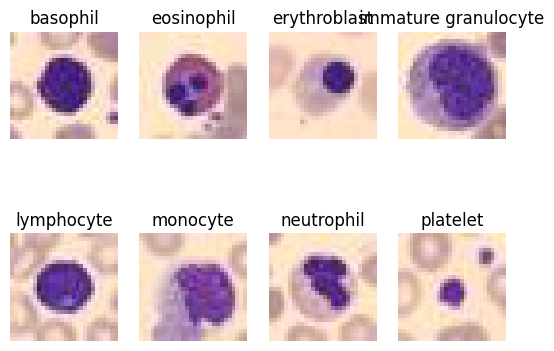

In [73]:
# Plot one example per cell type
for i in range(8):
    plt.subplot(2, 4, i + 1) # subplot starts at 1 
    plt.imshow(X_train_img[y_train == i][0]) #y_train as a boolean mask to select the first image of each cell type
    plt.title(class_names[i])
    plt.axis("off")


# Number of images per cell type
for i in range(8):
    print(f"{class_names[i]}: {np.sum(y_train == i)}")

*Your answer:* 

The Dataset is not balanced since some classes only get covered by a few hundred images (i.e, basophil with 852 training images) while other classes have more than two thousand images (i.e, neutrophil with 2330 training images). This may lead to different success rates concering the rightful assignment of the class labels. 

# 2)
Convolutions and pooling by hand. (7 points)

**How a convolution is computed.** A convolution takes a small matrix of weights, the *kernel*, and slides it over the image:

1. Place the kernel on the top-left corner of the image.
2. Multiply each kernel weight with the pixel below it and **sum** all these products. The sum is one value of the output.
3. Move the kernel `stride` pixels to the right and repeat. At the end of a row, go back to the left and move `stride` pixels down.

Example with a 4 × 4 image $x$ and a 2 × 2 kernel $k$ (stride 1, no padding):

$$x = \begin{pmatrix} \mathbf{1} & \mathbf{2} & 0 & 1 \\ \mathbf{0} & \mathbf{1} & 3 & 1 \\ 2 & 1 & 0 & 0 \\ 1 & 0 & 1 & 2 \end{pmatrix} \qquad k = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix} \qquad out = \begin{pmatrix} \mathbf{0} & -1 & -1 \\ -1 & 1 & 3 \\ 2 & 0 & -2 \end{pmatrix}$$

The first output value comes from the bold patch: $1\cdot1 + 2\cdot0 + 0\cdot0 + 1\cdot(-1) = 0$. One step to the right, the patch is $\begin{pmatrix} 2 & 0 \\ 1 & 3 \end{pmatrix}$, which gives $2 - 3 = -1$, and so on.

- **Stride:** with stride 2 the kernel jumps 2 pixels each time, so only every second position is computed and the output gets smaller: here $\begin{pmatrix} 0 & -1 \\ 2 & -2 \end{pmatrix}$.
- **Padding:** `pad` rows/columns of zeros are added around the image before sliding, so that the kernel also fits on the border pixels and the output does not shrink as much.

## a) Convolution (3 points)
Implement this as a function `conv(x, kernel, stride, pad)`:

- `x`: a two-dimensional array of size `(H, W)`.
- `kernel`: convolution kernel of size `(K, K)`.
- `stride`: the step the kernel moves each time, 0 < stride ≤ min(H, W).
- `pad`: number of zero rows/columns added to each side of the array, pad ≥ 0 (`np.pad` can help).

The function should return `out`, the result of convolving `x`, with dimensions `(H', W')`:

$$H' = \left\lfloor \frac{H + 2\cdot pad - K}{stride} \right\rfloor + 1 \qquad W' = \left\lfloor \frac{W + 2\cdot pad - K}{stride} \right\rfloor + 1$$

Use loops and numpy, not a library convolution function.

In [74]:
# Define convolution function
def conv(x, kernel, stride=1, pad=0):
    
    h, w = x.shape 
    
    x = np.pad(x, pad, mode='constant') # Pad the input image with zeros
    
    h_new = (h + 2 * pad - kernel.shape[0]) // stride + 1 # // floor division
    w_new = (w + 2 * pad - kernel.shape[1]) // stride + 1
    
    out = np.zeros((h_new, w_new)) # Initialize output array
    
    for i in range(h_new):
        for j in range(w_new):
            out[i, j] = np.sum(x[i*stride:i*stride+kernel.shape[0], j*stride:j*stride+kernel.shape[1]] * kernel)

    return out

In [75]:
# Test your function on the example above
x_ex = np.array([[1, 2, 0, 1], [0, 1, 3, 1], [2, 1, 0, 0], [1, 0, 1, 2]])
k_ex = np.array([[1, 0], [0, -1]])
print(conv(x_ex, k_ex, stride=1, pad=0))   # should be [[ 0. -1. -1.] [-1.  1.  3.] [ 2.  0. -2.]]
print(conv(x_ex, k_ex, stride=2, pad=0))   # should be [[ 0. -1.] [ 2. -2.]]

# ... and on a slightly bigger one
a = np.arange(9).reshape((3, 3))
M = np.block([[a, a], [a, a]])
print(M)
print(conv(M, np.ones((2, 2)), stride=2, pad=0))   # should be [[ 8. 10. 12.] [14. 16. 18.] [20. 22. 24.]]
print(conv(M, np.ones((3, 3)), stride=1, pad=1).shape)  # should be (6, 6)

[[ 0. -1. -1.]
 [-1.  1.  3.]
 [ 2.  0. -2.]]
[[ 0. -1.]
 [ 2. -2.]]
[[0 1 2 0 1 2]
 [3 4 5 3 4 5]
 [6 7 8 6 7 8]
 [0 1 2 0 1 2]
 [3 4 5 3 4 5]
 [6 7 8 6 7 8]]
[[ 8. 10. 12.]
 [14. 16. 18.]
 [20. 22. 24.]]
(6, 6)


## Sobel filters
A **Sobel filter** is a classic hand-designed kernel that detects **edges**. An edge is a place where the brightness changes quickly, i.e. where the derivative of the image is large. The Sobel kernel approximates this derivative:

$$S_x = \begin{pmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{pmatrix} \qquad S_y = \begin{pmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ 1 & 2 & 1 \end{pmatrix} = S_x^T$$

- Each row of $S_x$ computes *right neighbour − left neighbour*, a discrete derivative in x-direction. The rows are weighted 1-2-1, which averages over three rows and makes the filter less sensitive to noise.
- $S_x$ therefore responds to **vertical** edges (brightness changes from left to right), $S_y$ to **horizontal** edges. In flat regions both give 0. The sign tells the direction of the change (dark → bright or bright → dark).
- Combining both gives the edge strength in any direction: $G = \sqrt{G_x^2 + G_y^2}$, where $G_x$ and $G_y$ are the convolution results.

In a CNN, the kernels are not designed by hand but *learned*, and the first layer of a trained CNN often ends up with edge detectors very similar to Sobel filters.

Run the next cell to see the filter on an image with a single vertical edge (dark left half, bright right half):

In [76]:
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])
sobel_y = sobel_x.T

step = np.zeros((5, 5))
step[:, 3:] = 1
print(step)
print(conv(step, sobel_x, stride=1, pad=0))   # large values where the edge is
print(conv(step, sobel_y, stride=1, pad=0))   # no horizontal edge -> all 0

[[0. 0. 0. 1. 1.]
 [0. 0. 0. 1. 1.]
 [0. 0. 0. 1. 1.]
 [0. 0. 0. 1. 1.]
 [0. 0. 0. 1. 1.]]
[[0. 4. 4.]
 [0. 4. 4.]
 [0. 4. 4.]]
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]


## b) Edges of a blood cell (1 point)
Convert one cell image to grayscale (average over the colour channels and divide by 255). Apply both Sobel filters (stride 1, padding 1) and compute the edge strength $G$. Plot the grayscale image, $G_x$, $G_y$ and $G$ next to each other. (The bright frame at the border of $G$ is an artefact of the zero padding: the image suddenly "drops" to 0 there.)

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

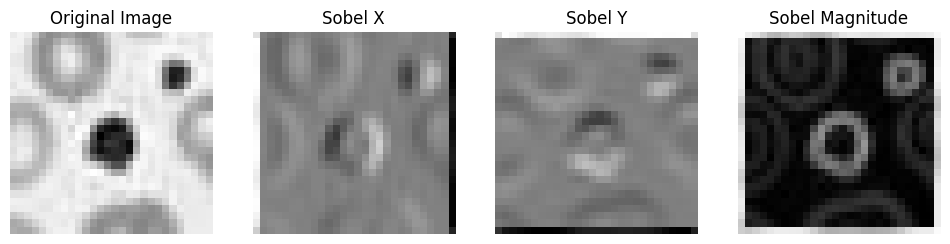

In [77]:
img = X_train_img[0]
# Convert to grayscale
img = np.mean(img, axis=2)  # average over the color channels (third channel: (R+G+B)/3)

# Apply Sobel filters
img_sobel_x = conv(img, sobel_x, stride=1, pad=1)
img_sobel_y = conv(img, sobel_y, stride=1, pad=1)
img_sobel_magnitude = np.sqrt(img_sobel_x**2 + img_sobel_y**2)

# Display results
plt.figure(figsize=(12, 4))
plt.subplot(1, 4, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(img_sobel_x, cmap='gray')
plt.title('Sobel X')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(img_sobel_y, cmap='gray')
plt.title('Sobel Y')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(img_sobel_magnitude, cmap='gray')
plt.title('Sobel Magnitude')
plt.axis('off')

## c) Compare with PyTorch (1 point)
In a CNN you would not write the convolution yourself but use a layer of the library, which calls `torch.nn.functional.conv2d`. Apply `sobel_x` to the same grayscale image with `F.conv2d` (stride 1, padding 1) and check that you get the same result as with your `conv` (e.g. with `np.allclose`). Note that `F.conv2d` expects tensors of shape `(batch, channels, H, W)` for the image and `(out_channels, in_channels, K, K)` for the kernel.

**Question:** Using the formula from a), what output size do you expect for the 28 × 28 image and the 3 × 3 Sobel kernel (i) with stride 1 and padding 1, (ii) with stride 1 and no padding, (iii) with stride 2 and padding 1? Check your answers with `conv` or `F.conv2d`. What is the padding good for?

In [78]:
# Apply sobel_x with F.conv2d and compare with your result
img_t = torch.tensor(img, dtype=torch.float32).reshape(1, 1, 28, 28)
k_t   = torch.tensor(sobel_x, dtype=torch.float32).reshape(1, 1, 3, 3)

out_torch = F.conv2d(img_t, k_t, stride=1, padding=1)   # Form (1, 1, 28, 28)
out_mine  = conv(img, sobel_x, stride=1, pad=1)         # Form (28, 28)

# Check the output sizes
print(out_torch.shape)  # (1, 1, 28, 28)
print(out_mine.shape)   # (28, 28)

torch.Size([1, 1, 28, 28])
(28, 28)


*Your answer:*

(i) Output size: (28,28)
(ii) Output size: (26,26)
(iii) Output size: (14,14)

Padding is good for when you don't want your output size to differ from your input image size. So there will be no smaller image.


## d) Max pooling (1 point)
Implement `max_pool(x, size)`: split the array into non-overlapping `size × size` blocks (stride = size, no padding) and keep the maximum of each block. Apply it with `size=2` and `size=4` to the edge strength $G$ from b) and plot the results.

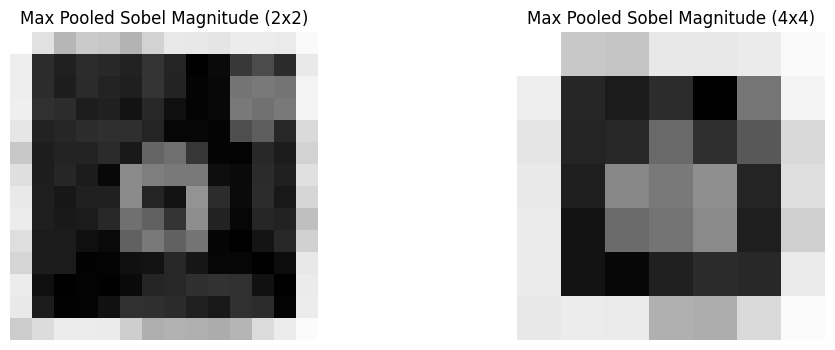

In [79]:
def max_pool(x, size):
    h, w = x.shape
    h_new = h // size
    w_new = w // size
    out = np.zeros((h_new, w_new))
    for i in range(h_new):
        for j in range(w_new):
            out[i, j] = np.max(x[i*size:(i+1)*size, j*size:(j+1)*size])
    return out

# Apply to G and plot
img_sobel_magnitude_pool_2 = max_pool(img_sobel_magnitude, size=2)
img_sobel_magnitude_pool_4 = max_pool(img_sobel_magnitude, size=4)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.imshow(img_sobel_magnitude_pool_2, cmap='gray')
plt.title('Max Pooled Sobel Magnitude (2x2)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_sobel_magnitude_pool_4, cmap='gray')
plt.title('Max Pooled Sobel Magnitude (4x4)')
plt.axis('off')

plt.show()

## e) Pooling and translation (1 point)
Move the cell image 1 pixel to the right (`np.roll(gray, 1, axis=1)`) and compute its edge strength $G_{shifted}$ again. Compare how much the result changes, before and after pooling, with the relative difference

$$\text{change} = \frac{\text{mean}(|A - B|)}{\text{mean}(|A|)}$$

once for $A = G$, $B = G_{shifted}$ and once for $A = $ `max_pool(G, 4)`, $B = $ `max_pool(G_shifted, 4)`.

**Question:** What do you observe? Explain how this relates to the translation invariance from the lecture, and why it is useful for classifying cells.

Changes without Pooling (4x4): 0.253
Changes with Pooling (4x4): 0.032


(np.float64(-0.5), np.float64(6.5), np.float64(6.5), np.float64(-0.5))

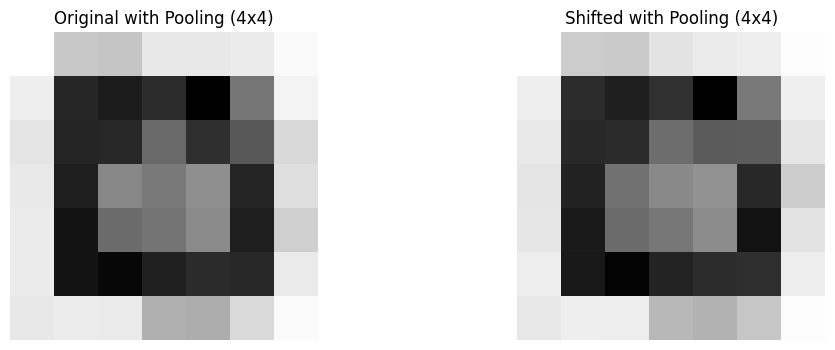

In [80]:
# Shift the image, compute the edge strength and compare before/after pooling
img_shifted = np.roll(img, shift=1, axis=1)  # Shift the image to the right by 1 pixel

img_shifted_sobel_x = conv(img_shifted, sobel_x, stride=1, pad=1)
img_shifted_sobel_y = conv(img_shifted, sobel_y, stride=1, pad=1)
img_shifted_sobel_magnitude = np.sqrt(img_shifted_sobel_x**2 + img_shifted_sobel_y**2)

def change(A, B):
    return np.mean(np.abs(A - B)) / np.mean(np.abs(A))

G = img_sobel_magnitude # original magnitude
G_shifted = img_shifted_sobel_magnitude # shifted magnitude

change_before = change(G, G_shifted) # difference before pooling
change_after  = change(max_pool(G, 4), max_pool(G_shifted, 4)) # difference after pooling (4x4)

print(f"Changes without Pooling (4x4): {change_before:.3f}")
print(f"Changes with Pooling (4x4): {change_after:.3f}")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.imshow(max_pool(G, 4), cmap='gray')
plt.title('Original with Pooling (4x4)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(max_pool(G_shifted, 4), cmap='gray')
plt.title('Shifted with Pooling (4x4)')
plt.axis('off')

*Your answer:*

Both max_pooled images look fairly similiar. This is also underlined with the change function depicting the smaller number of change (0.032) between the two images when max_pooled by 4x4. Whereas, without pooling, both images show a difference of 0.253 according to the change function. A translation is invariant when its output has small to almost none changes when the input is shifted. This is highly useful for classifying cells as a cell can be anywhere in the picture but what matters is its form and structure (what kind of cell it is rather than its location). Hence, Max pooling focues on the signal itself.

# 3)
Train an autoencoder to reconstruct the blood cell images. (5 points)

The autoencoder is a fully connected network (like the MLP in exercise 2) on the flattened RGB images:
- **Encoder**: 2352 pixels (28 × 28 × 3) → 128 → 16 dimensions
- **Decoder**: 16 → 128 → 2352 pixels

Use ReLU activations in the hidden layers, and a sigmoid in the last layer so that the outputs are between 0 and 1 like the pixel values. The bottleneck (16 dimensions) forces the network to learn a compressed representation of the cells.

We provide the data preparation and the function `train_model`, which trains a model with the Adam optimizer and returns the training and test loss of every epoch. You don't have to change it. Training should take about a minute on a CPU.

In [81]:
# Flatten the images and scale them to [0, 1]
X_train = torch.tensor(X_train_img.reshape(len(X_train_img), -1) / 255.0, dtype=torch.float32)
X_test = torch.tensor(X_test_img.reshape(len(X_test_img), -1) / 255.0, dtype=torch.float32)
input_dim = X_train.shape[1]
print(X_train.shape, X_test.shape)


def train_model(model, loss_fn, X_train, X_test, epochs=20, batch_size=128, lr=1e-3):
    # loss_fn(model, x) must return the (scalar) loss of the model on the batch x
    loader = DataLoader(TensorDataset(X_train), batch_size=batch_size, shuffle=True)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    train_losses, test_losses = [], []
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for (xb,) in loader:
            optimizer.zero_grad()
            loss = loss_fn(model, xb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        train_losses.append(total / len(X_train))
        model.eval()
        with torch.no_grad():
            test_losses.append(loss_fn(model, X_test).item())
        print(f"epoch {epoch + 1:2d}  train loss {train_losses[-1]:.4f}  test loss {test_losses[-1]:.4f}")
    return train_losses, test_losses

torch.Size([11959, 2352]) torch.Size([3421, 2352])


## a) Model (2 points)
Complete the `Autoencoder` class: define `self.encoder` and `self.decoder` (e.g. with `nn.Sequential`), and the methods `forward` (input → reconstruction) and `encode` (input → 16-dimensional latent representation).

In [82]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, latent_dim=16):
        super().__init__()
        # Define self.encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), # 2352 -> 128
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim) # 128 -> 16
        )
        # Define self.decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim), # 16 -> 128
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim), # 128 -> 2352
            nn.Sigmoid() # compress to [0, 1] range for image reconstruction
        )

    def forward(self, x):
        z = self.encode(x) # compress
        x_recon = self.decode(z) # reconstruct
        return x_recon

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z)

# Initialize model
model = Autoencoder(input_dim=2352)


## b) Training (1 point)
Define the loss function `ae_loss(model, x)`, which returns the MSE between the reconstruction and the input, train the autoencoder for 20 epochs with `train_model` and plot the training and test loss over the epochs.

epoch  1  train loss 0.0258  test loss 0.0144
epoch  2  train loss 0.0132  test loss 0.0128
epoch  3  train loss 0.0123  test loss 0.0116
epoch  4  train loss 0.0109  test loss 0.0104
epoch  5  train loss 0.0101  test loss 0.0098
epoch  6  train loss 0.0096  test loss 0.0093
epoch  7  train loss 0.0092  test loss 0.0091
epoch  8  train loss 0.0089  test loss 0.0088
epoch  9  train loss 0.0086  test loss 0.0085
epoch 10  train loss 0.0084  test loss 0.0083
epoch 11  train loss 0.0082  test loss 0.0081
epoch 12  train loss 0.0080  test loss 0.0080
epoch 13  train loss 0.0079  test loss 0.0079
epoch 14  train loss 0.0077  test loss 0.0078
epoch 15  train loss 0.0076  test loss 0.0076
epoch 16  train loss 0.0075  test loss 0.0075
epoch 17  train loss 0.0074  test loss 0.0074
epoch 18  train loss 0.0073  test loss 0.0074
epoch 19  train loss 0.0072  test loss 0.0072
epoch 20  train loss 0.0071  test loss 0.0072


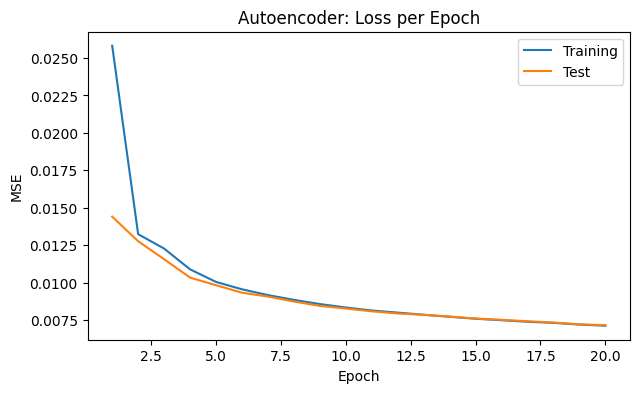

In [83]:
def ae_loss(model, x):
    x_recon = model(x)
    return F.mse_loss(x_recon, x)

# Train the model
model = Autoencoder(input_dim=2352) 
train_losses, test_losses = train_model(model, ae_loss, X_train, X_test, epochs=20)

# Plot the loss curves
plt.figure(figsize=(7, 4))
plt.plot(range(1, 21), train_losses, label="Training")
plt.plot(range(1, 21), test_losses, label="Test")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Autoencoder: Loss per Epoch")
plt.legend()
plt.show()

## c) Reconstructions (1 point)
Reconstruct the test images and plot 8 original test images (top row) above their reconstructions (bottom row). Remember to reshape the vectors back to `(28, 28, 3)` images.

**Question:** What details of the cells are lost in the reconstructions, and why? Think about what the 16-dimensional bottleneck forces the network to do and what the MSE loss rewards.

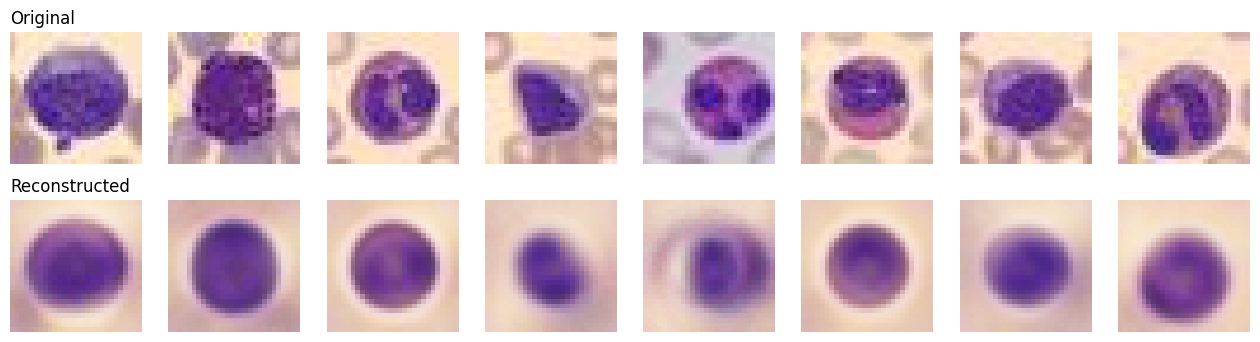

In [91]:
# Reconstruct the test images
model.eval()
with torch.no_grad():
    x = X_test[:8]              # 8 test images (8, 2352)
    x_recon = model(x)          # reconstructed images (8, 2352)

# Visualize original vs reconstructed
plt.figure(figsize=(16, 4))
for i in range(8):
    # Original
    plt.subplot(2, 8, i + 1)
    plt.imshow(x[i].reshape(28, 28, 3).numpy())
    plt.axis("off")
    if i == 0:
        plt.title("Original", loc="left")

    # Reconstructed
    plt.subplot(2, 8, i + 9)
    plt.imshow(x_recon[i].reshape(28, 28, 3).numpy())
    plt.axis("off")
    if i == 0:
        plt.title("Reconstructed", loc="left")
plt.show()

*Your answer:*

The reconstructed images are smoother than their original and details that to not contribute of classifying the right labels are nearly gone, i.e the smaller background cells. Since the model needs to compress the images into 16 single numbers, it only keeps the neccessary attributes of identifying the cell, hence minimizing the loss. 

# 4)
Turn the autoencoder into a variational autoencoder (VAE). (7 points)

As in the lecture, the encoder of a VAE does not output one point z, but the mean $\mu$ and the standard deviation $\sigma$ of a normal distribution for each of the 16 latent variables. The latent representation z is then **sampled** from this distribution and decoded.

In practice the encoder outputs $\log\sigma^2$ instead of $\sigma$: a linear layer can output any number, but $\sigma$ must be positive. Taking the exponential, $\sigma = \exp\left(\tfrac{1}{2}\log\sigma^2\right)$, guarantees that, and it is numerically more stable.

**The reparameterization trick.** We cannot backpropagate through "draw z at random": the gradient of a random draw with respect to $\mu$ and $\sigma$ is not defined. So we move the randomness out of the way: first draw $\varepsilon \sim \mathcal{N}(0, 1)$, which does not depend on any parameter, and then compute

$$z = \mu + \sigma \cdot \varepsilon, \qquad \sigma = \exp\left(\tfrac{1}{2}\log\sigma^2\right)$$

This z has exactly the distribution $\mathcal{N}(\mu, \sigma^2)$, but now z is a simple (differentiable) function of $\mu$ and $\sigma$, so the gradients can flow back into the encoder. (`torch.randn_like` draws $\varepsilon$ with the right shape.)

**The loss.** The VAE loss is the reconstruction loss plus the Kullback-Leibler (KL) divergence that penalises $\mu$ and $\sigma$ for being different from 0 and 1. For normal distributions the KL divergence has a closed form, which you can use directly (sum over the 16 latent dimensions, mean over the samples of the batch):

$$KL = -\frac{1}{2}\sum_{j=1}^{16}\left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$$

For the reconstruction loss use the squared error **summed** over the 2352 pixels (and averaged over the samples of the batch), so that it has the same scale as the KL term.

## a) Reparameterization (1 point)
We provide the VAE class, which uses the same layer sizes as your autoencoder. Implement the method `reparameterize`.

In [85]:
class VAE(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.ReLU())
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, input_dim), nn.Sigmoid())

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        # Your code
        return z

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar

## b) Loss (2 points)
Implement `vae_loss(model, x, beta=1.0)`, which returns reconstruction loss + `beta` × KL (the parameter `beta` lets us switch the KL term off in e)).

In [86]:
def vae_loss(model, x, beta=1.0):
    x_rec, mu, logvar = model(x)
    # Your code

## c) Training and generating new cells (1 point)
Train the VAE for 20 epochs with `train_model` (`loss_fn=vae_loss`). Then **generate** 8 new cell images: draw 8 random latent vectors $z \sim \mathcal{N}(0, I)$ (16-dimensional) and pass them through the decoder only. Plot them.

In [87]:
# Train the VAE

# Generate new cells from random latent vectors

## d) Comparing the latent spaces (2 points)
Encode the test images with the autoencoder (`encode`) and with the VAE (use $\mu$ as the latent representation). Reduce both 16-dimensional latent spaces to 2 dimensions with PCA and plot them side by side, coloured by cell type (with a legend).

**Question:** Do the cell types separate, although neither model ever saw the labels? How does the VAE latent space look different from the autoencoder latent space, and what part of the VAE causes this?

In [88]:
# Encode the test images

# PCA and plot

*Your answer:*

## e) What does the KL term do? (1 point)
Train a second VAE with `beta=0`, i.e. without the KL term (you can pass `lambda model, x: vae_loss(model, x, beta=0)` as `loss_fn`). Generate 8 new cells from random $z \sim \mathcal{N}(0, I)$ again and compare them with the ones from c).

**Question:** What happens to the generated images without the KL term, and why?

In [89]:
# Train a VAE without KL term

# Generate new cells and compare

*Your answer:*